In [ ]:
# Run relative to the repository root so data/, models/ and figures/ resolve.
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

In [10]:
import pandas as pd
import numpy as np

from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Load
df = pd.read_csv("data/data.csv")

# --- Drop sparse/contingent cols ---
drop_cols = [
    "Axes disrupted", 
    "Re-operation after this operation (add date)", 
    "Time to re-operation",
    "Recurrence date", 
    "Mortality (find date)",
    "radiation doses", "radiation timeframe (weeks)",
    "radiation doses.1", "radiation timeframe (weeks).1",
    "Tumor volume"   # <- drop derived column, we will recompute
]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# --- Define column groups ---
numeric_cols = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", 
    "Last BMI on file", "Length of followup"
]

binary_cols = [
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension", "CSF leak", "Mortality Y/N",
    "Prior operation", "recurring tumor?", "Recurrence after this operation",
    "Shunt (y/n) ", "Transient DI", "Permanent DI",
    "DDAVP (y/n) - most patients get periop, can do time frame (in hospital vs 1 mo vs 1 yr postop)",
    "DDAVP outside of hospital", "DDAVP ≥1 year", "Post-op new panhypopit",
    "Other vascular complication (need to specify)", "Hemorrhage or hemorrhagic stroke",
    "Ischemic Stroke", "Other intracranial infection", "Non-intracranial infection",
    "Meningitis", "Radiation post (y/n)", "prior radiation", "BRAF+"
]

multiclass_cols = [
    "Surgical Approach",
    "Tumor (Adamantinomatous, papillary)",
    "Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)",
    "Solid, cystic, mixed",
    "Resection outcome (total, subtotal, partial)",
    "Post-op visual improvement/stable/worse (subjective); should add something specific about visual fields if any patients have; add about visual acuity",
    "DDVAP Duration (In hospital, <1 year, >1 year)"
]

# --- Build transformers ---
numeric_transformer = Pipeline(steps=[
    ("imputer", IterativeImputer(random_state=42))
])

binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

multiclass_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# --- Preprocessor ---
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("bin", binary_transformer, binary_cols),
        ("multi", multiclass_transformer, multiclass_cols)
    ]
)

# --- Apply ---
X = preprocessor.fit_transform(df)

# Get feature names back
ohe_features = preprocessor.named_transformers_["multi"]["encoder"].get_feature_names_out(multiclass_cols)
all_features = numeric_cols + binary_cols + list(ohe_features)

df_clean = pd.DataFrame(X, columns=all_features)

# --- Recompute tumor volume ---
df_clean["Tumor volume"] = (4/3) * np.pi * (
    (df_clean["Tumor size"] / 2) *
    (df_clean["Tumor size.1"] / 2) *
    (df_clean["Tumor size.2"] / 2)
)

print(df_clean.shape)
print(df_clean.head())


(59, 62)
   Age        BMI  Tumor size  Tumor size.1  Tumor size.2  Last BMI on file  \
0  50.0  20.81000    0.900000      0.500000      0.400000         24.700000   
1  30.0  33.10000    2.700000      2.100000      2.000000         29.160000   
2  66.0  30.17956    2.476773      1.940629      1.914083         32.739442   
3  10.0  27.04000    2.897296      2.412568      3.052985         39.500000   
4  14.0  20.60000    2.371848      2.076279      2.165767         23.100000   

   Length of followup  \
0              5266.0   
1              1680.0   
2                18.0   
3              4574.0   
4               128.0   

   Pre-op visual impairment (y/n) - symptomatic complaint of visual loss  \
0                                                1.0                       
1                                                0.0                       
2                                                1.0                       
3                                                1.0         

In [2]:
df_clean.to_csv("data/data_clean.csv", index=False)

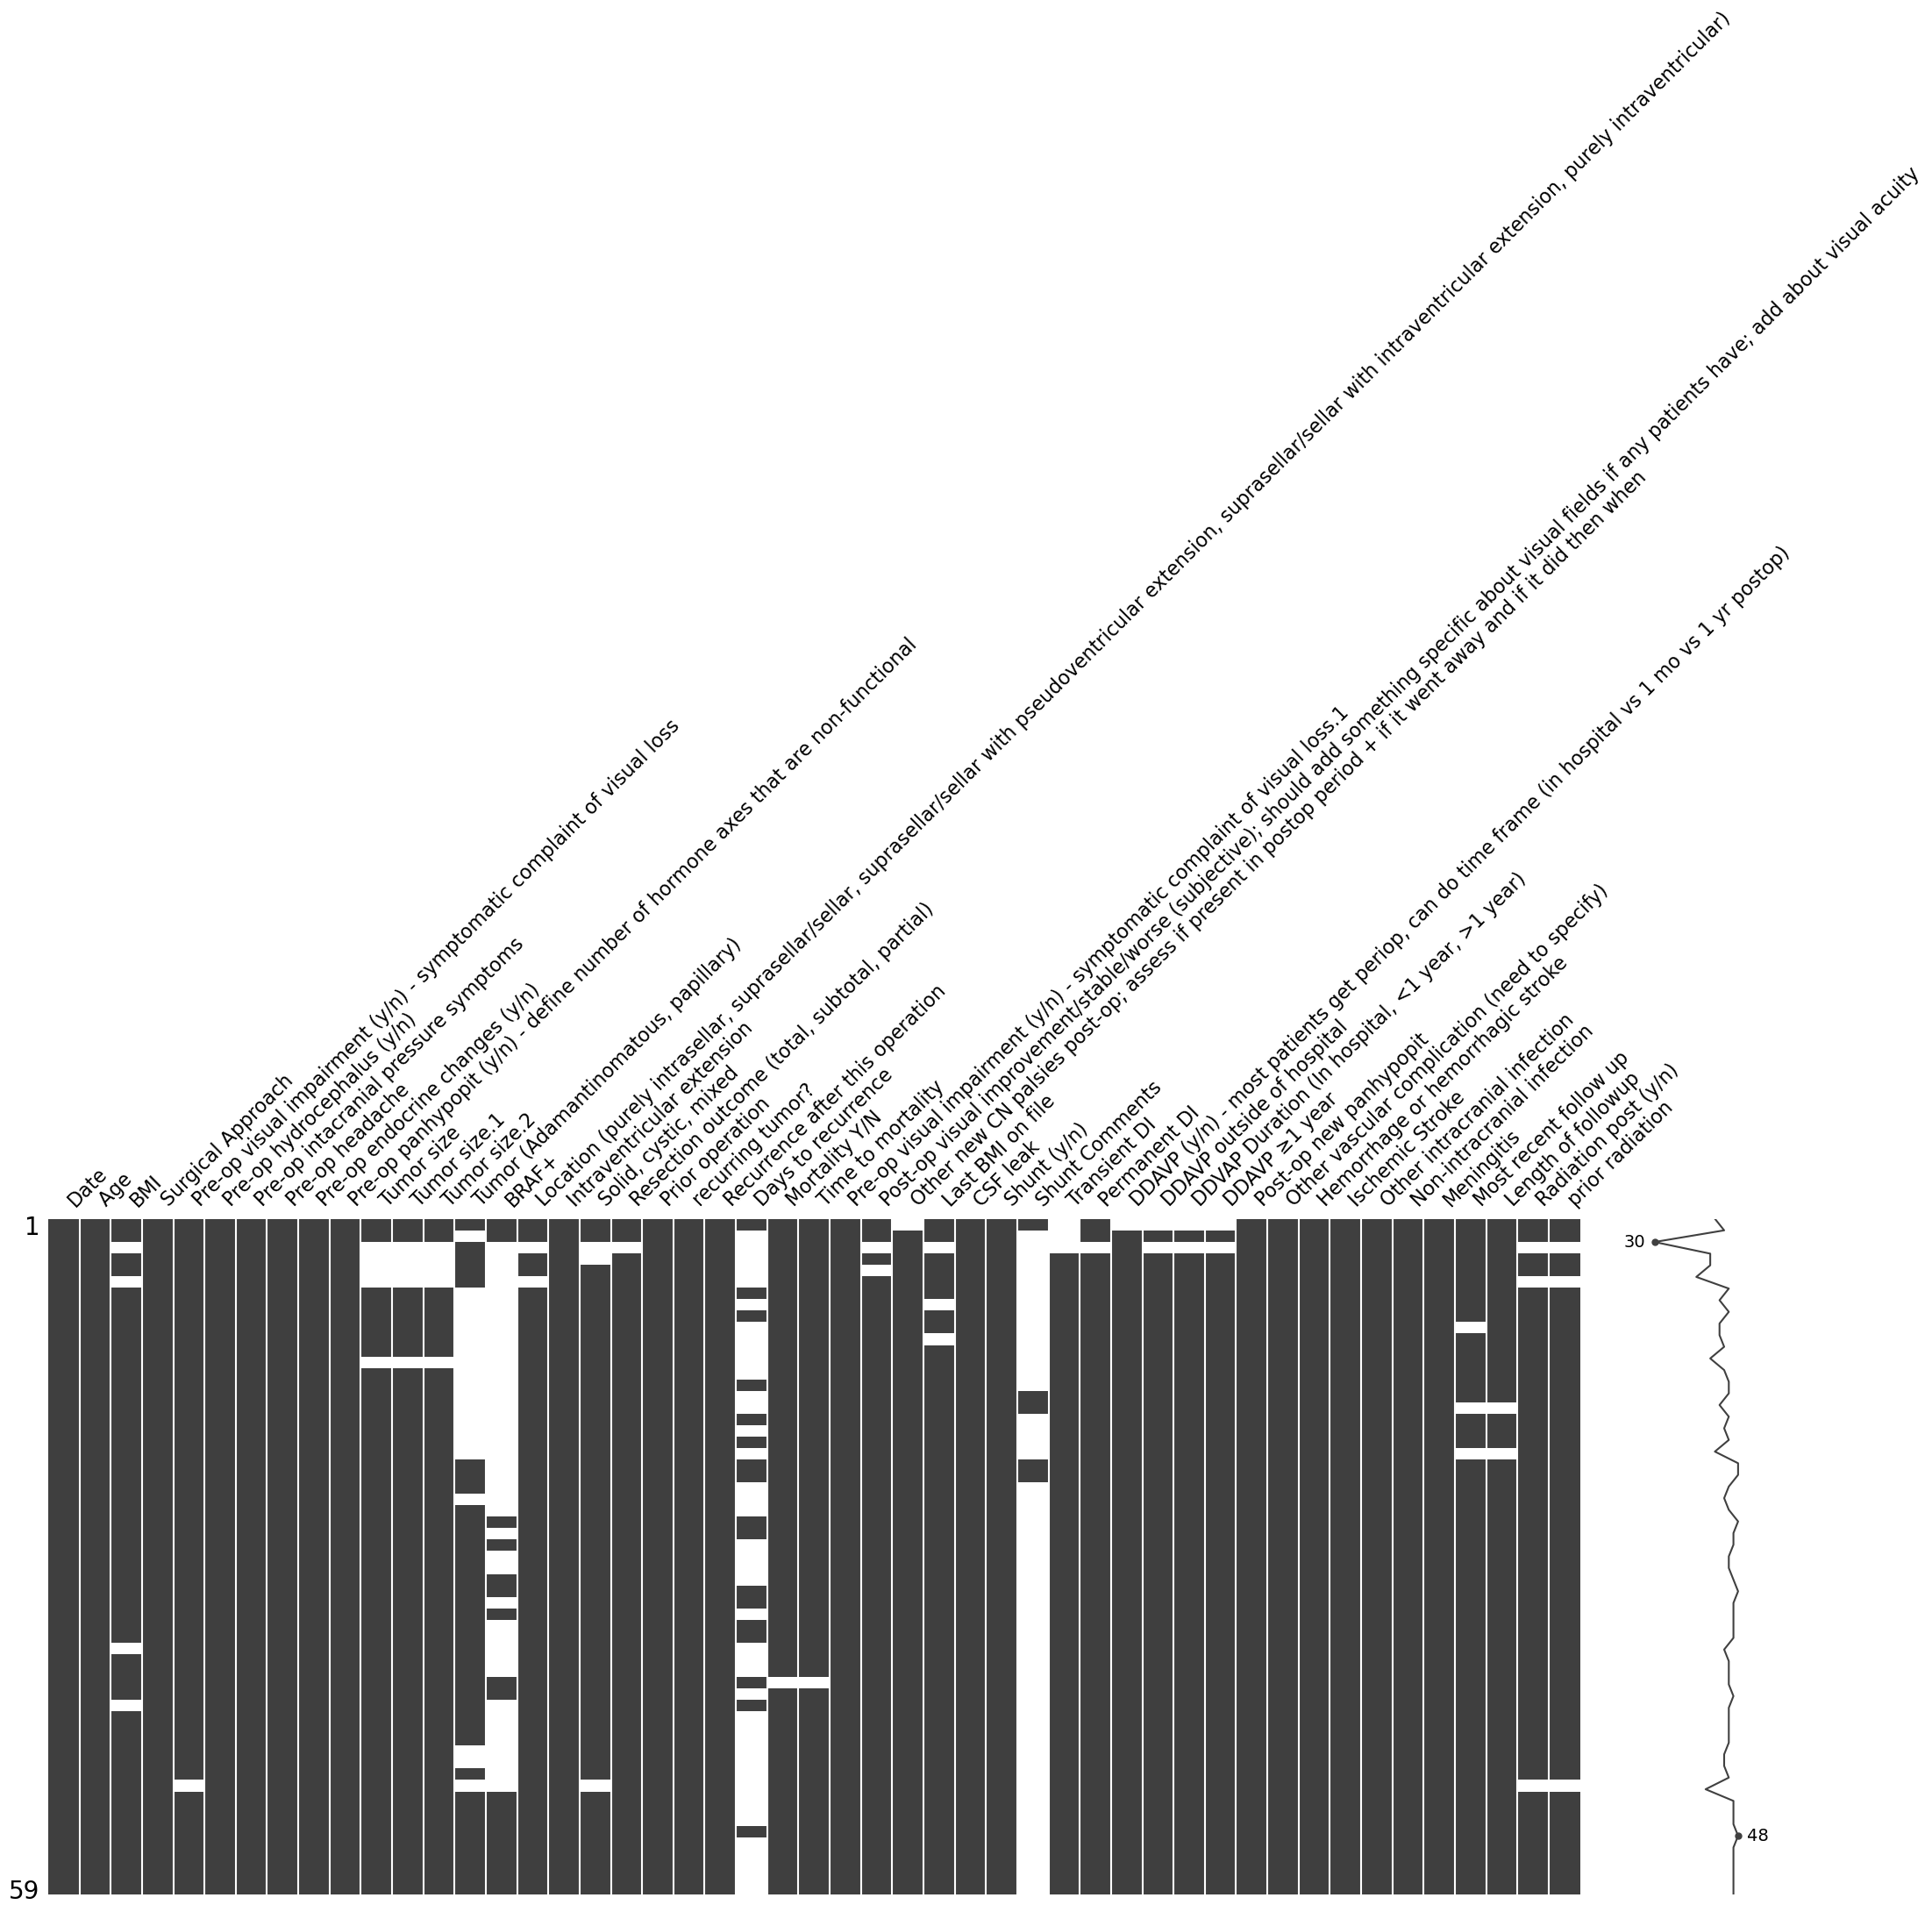

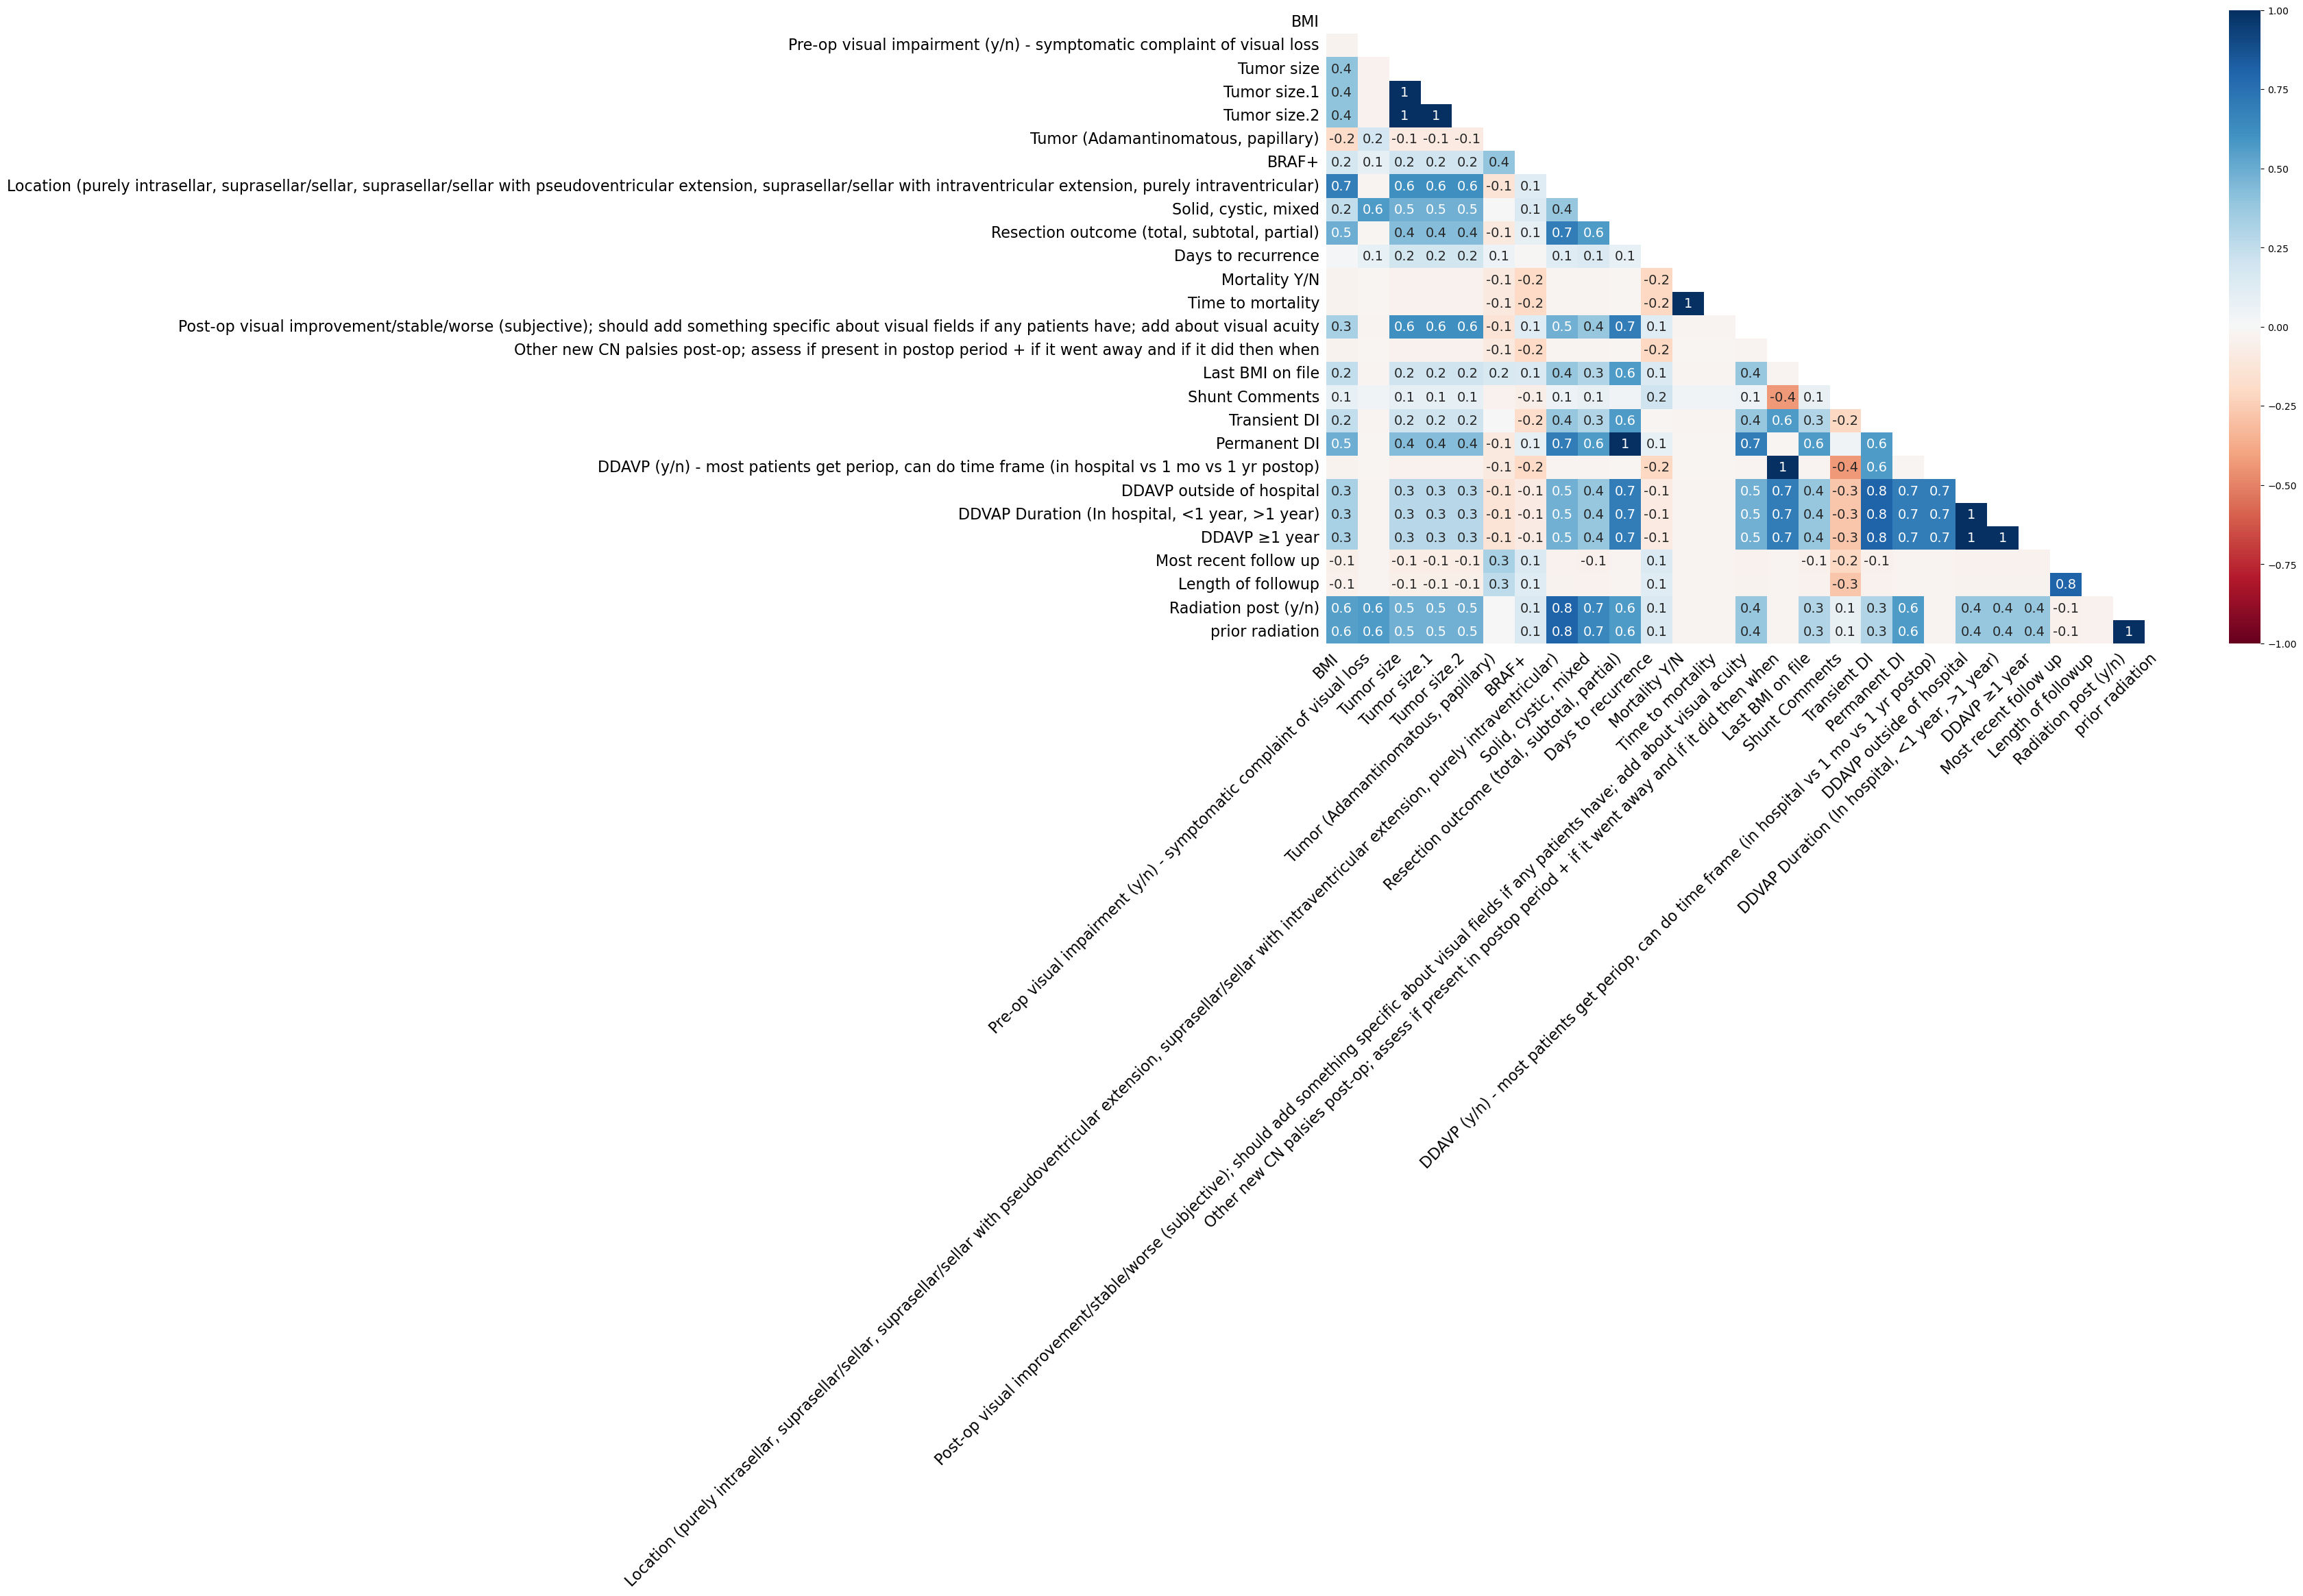

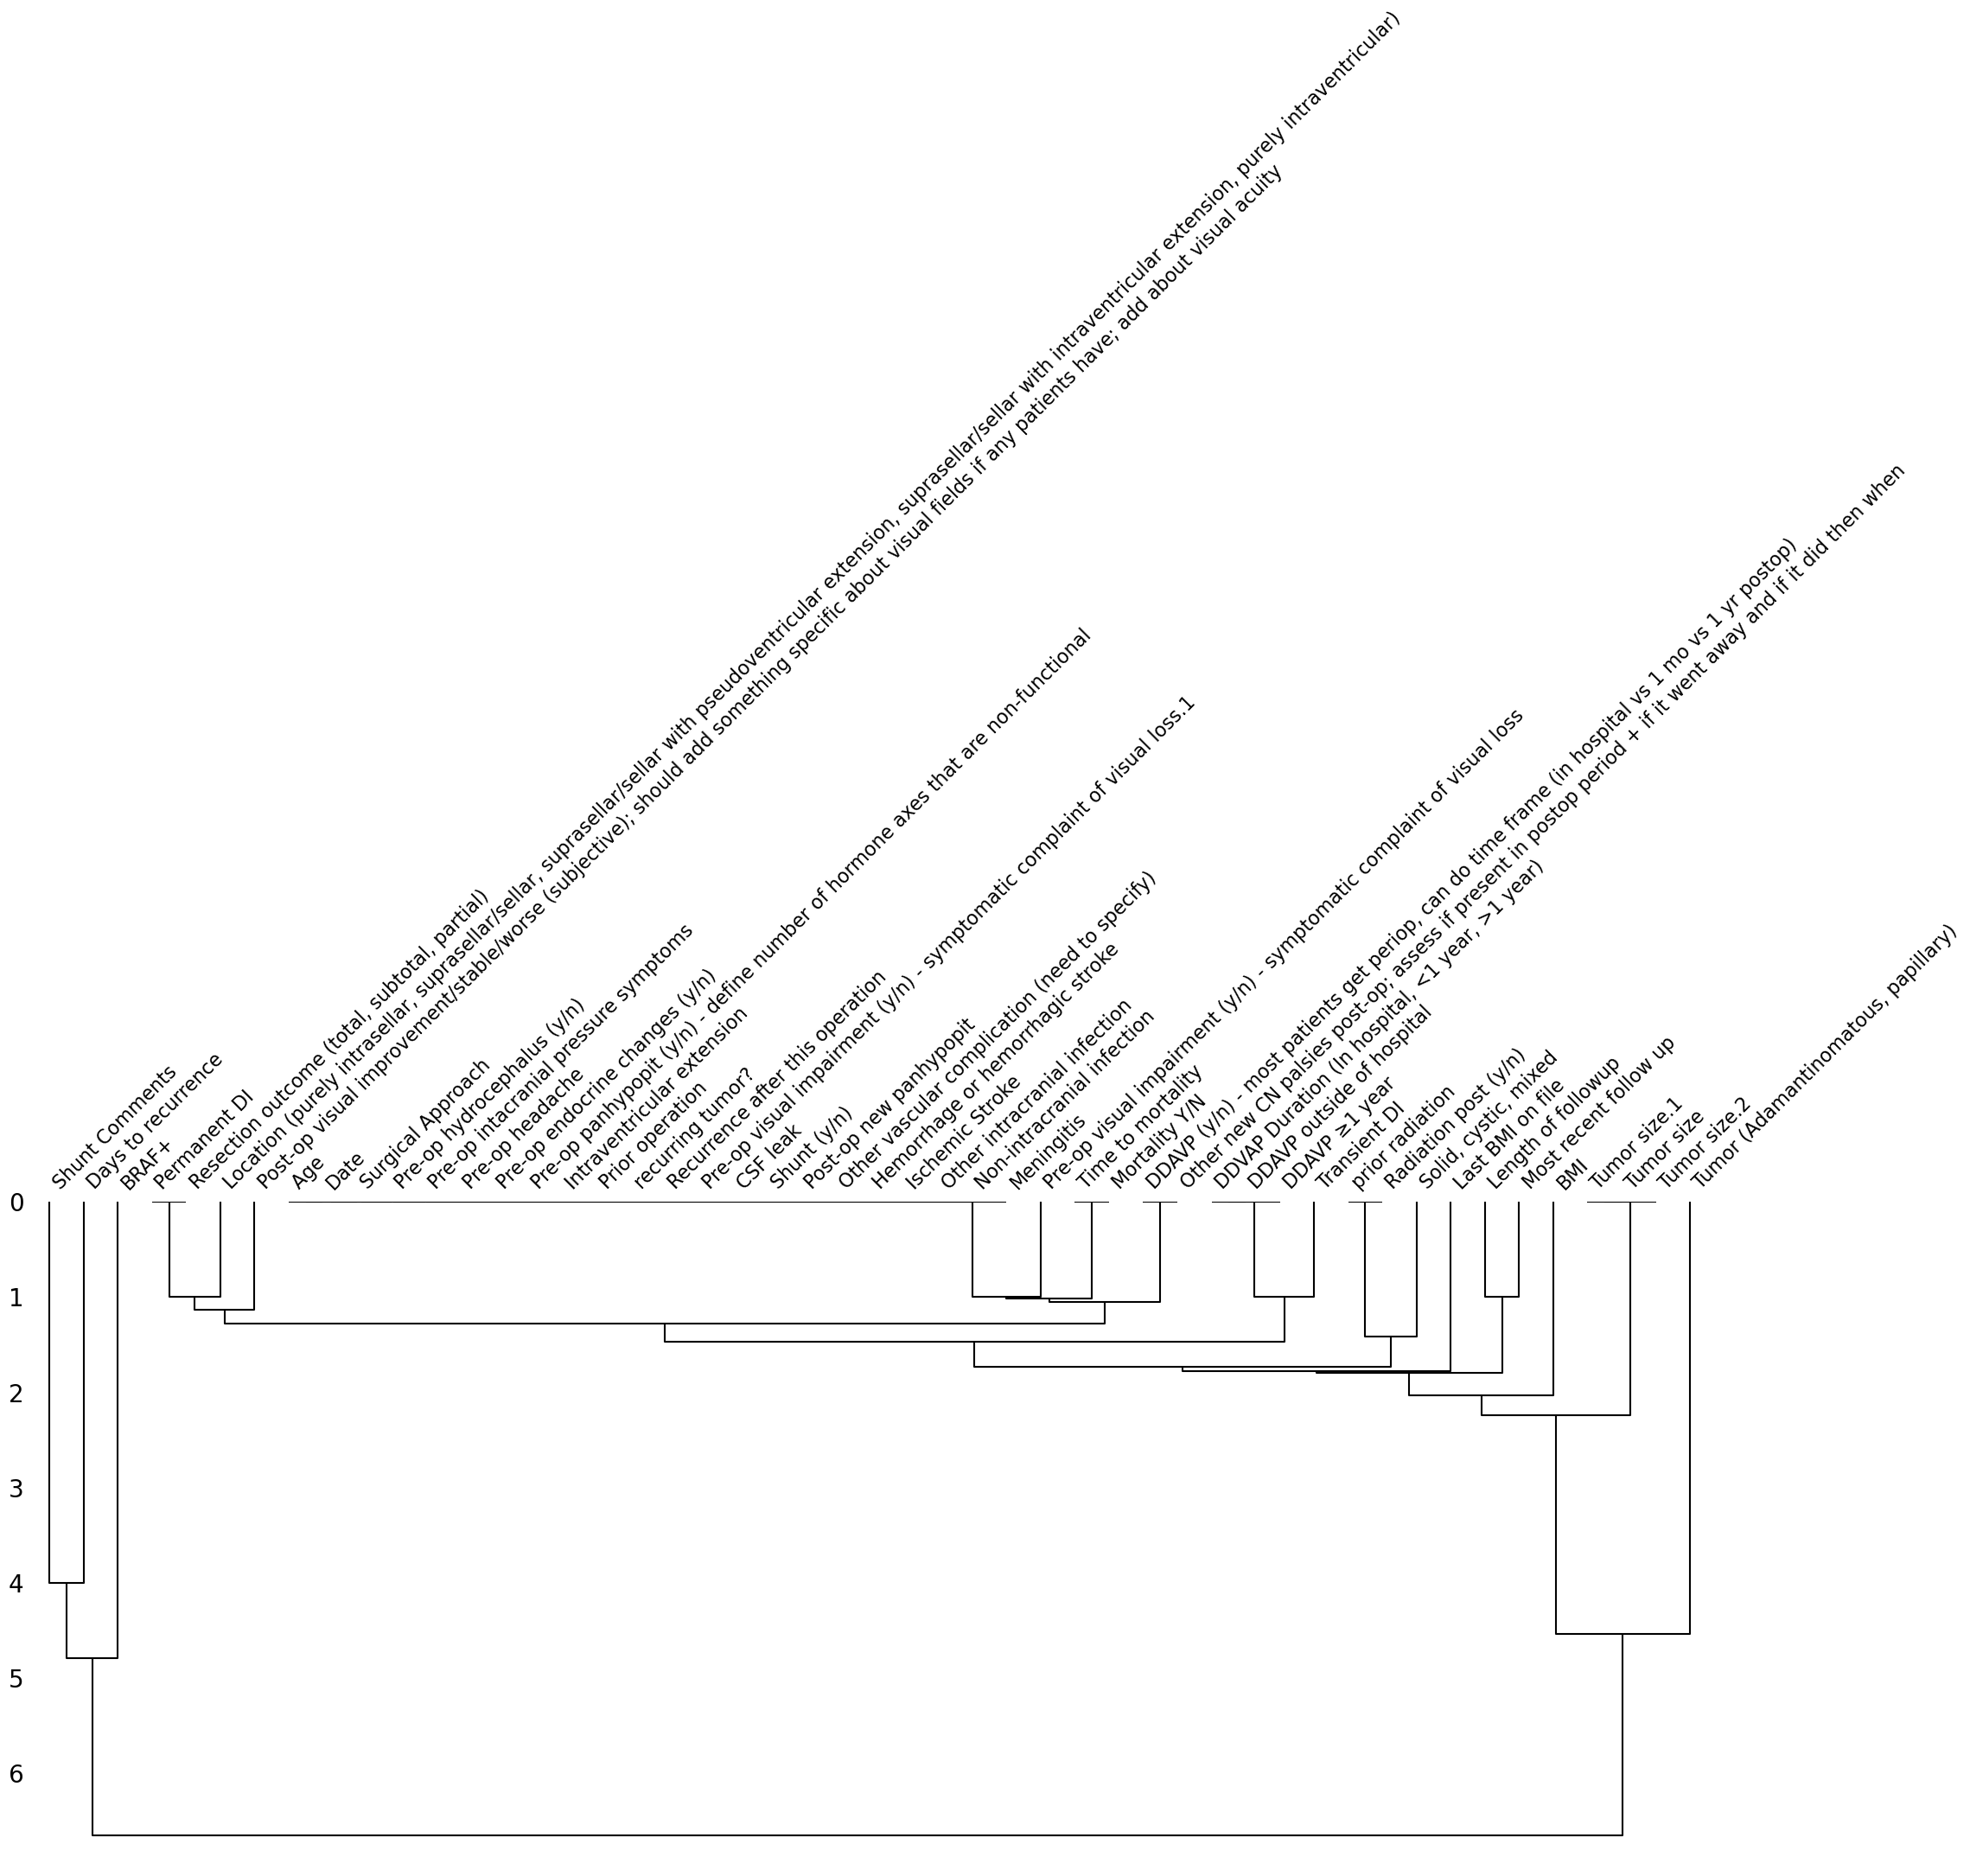

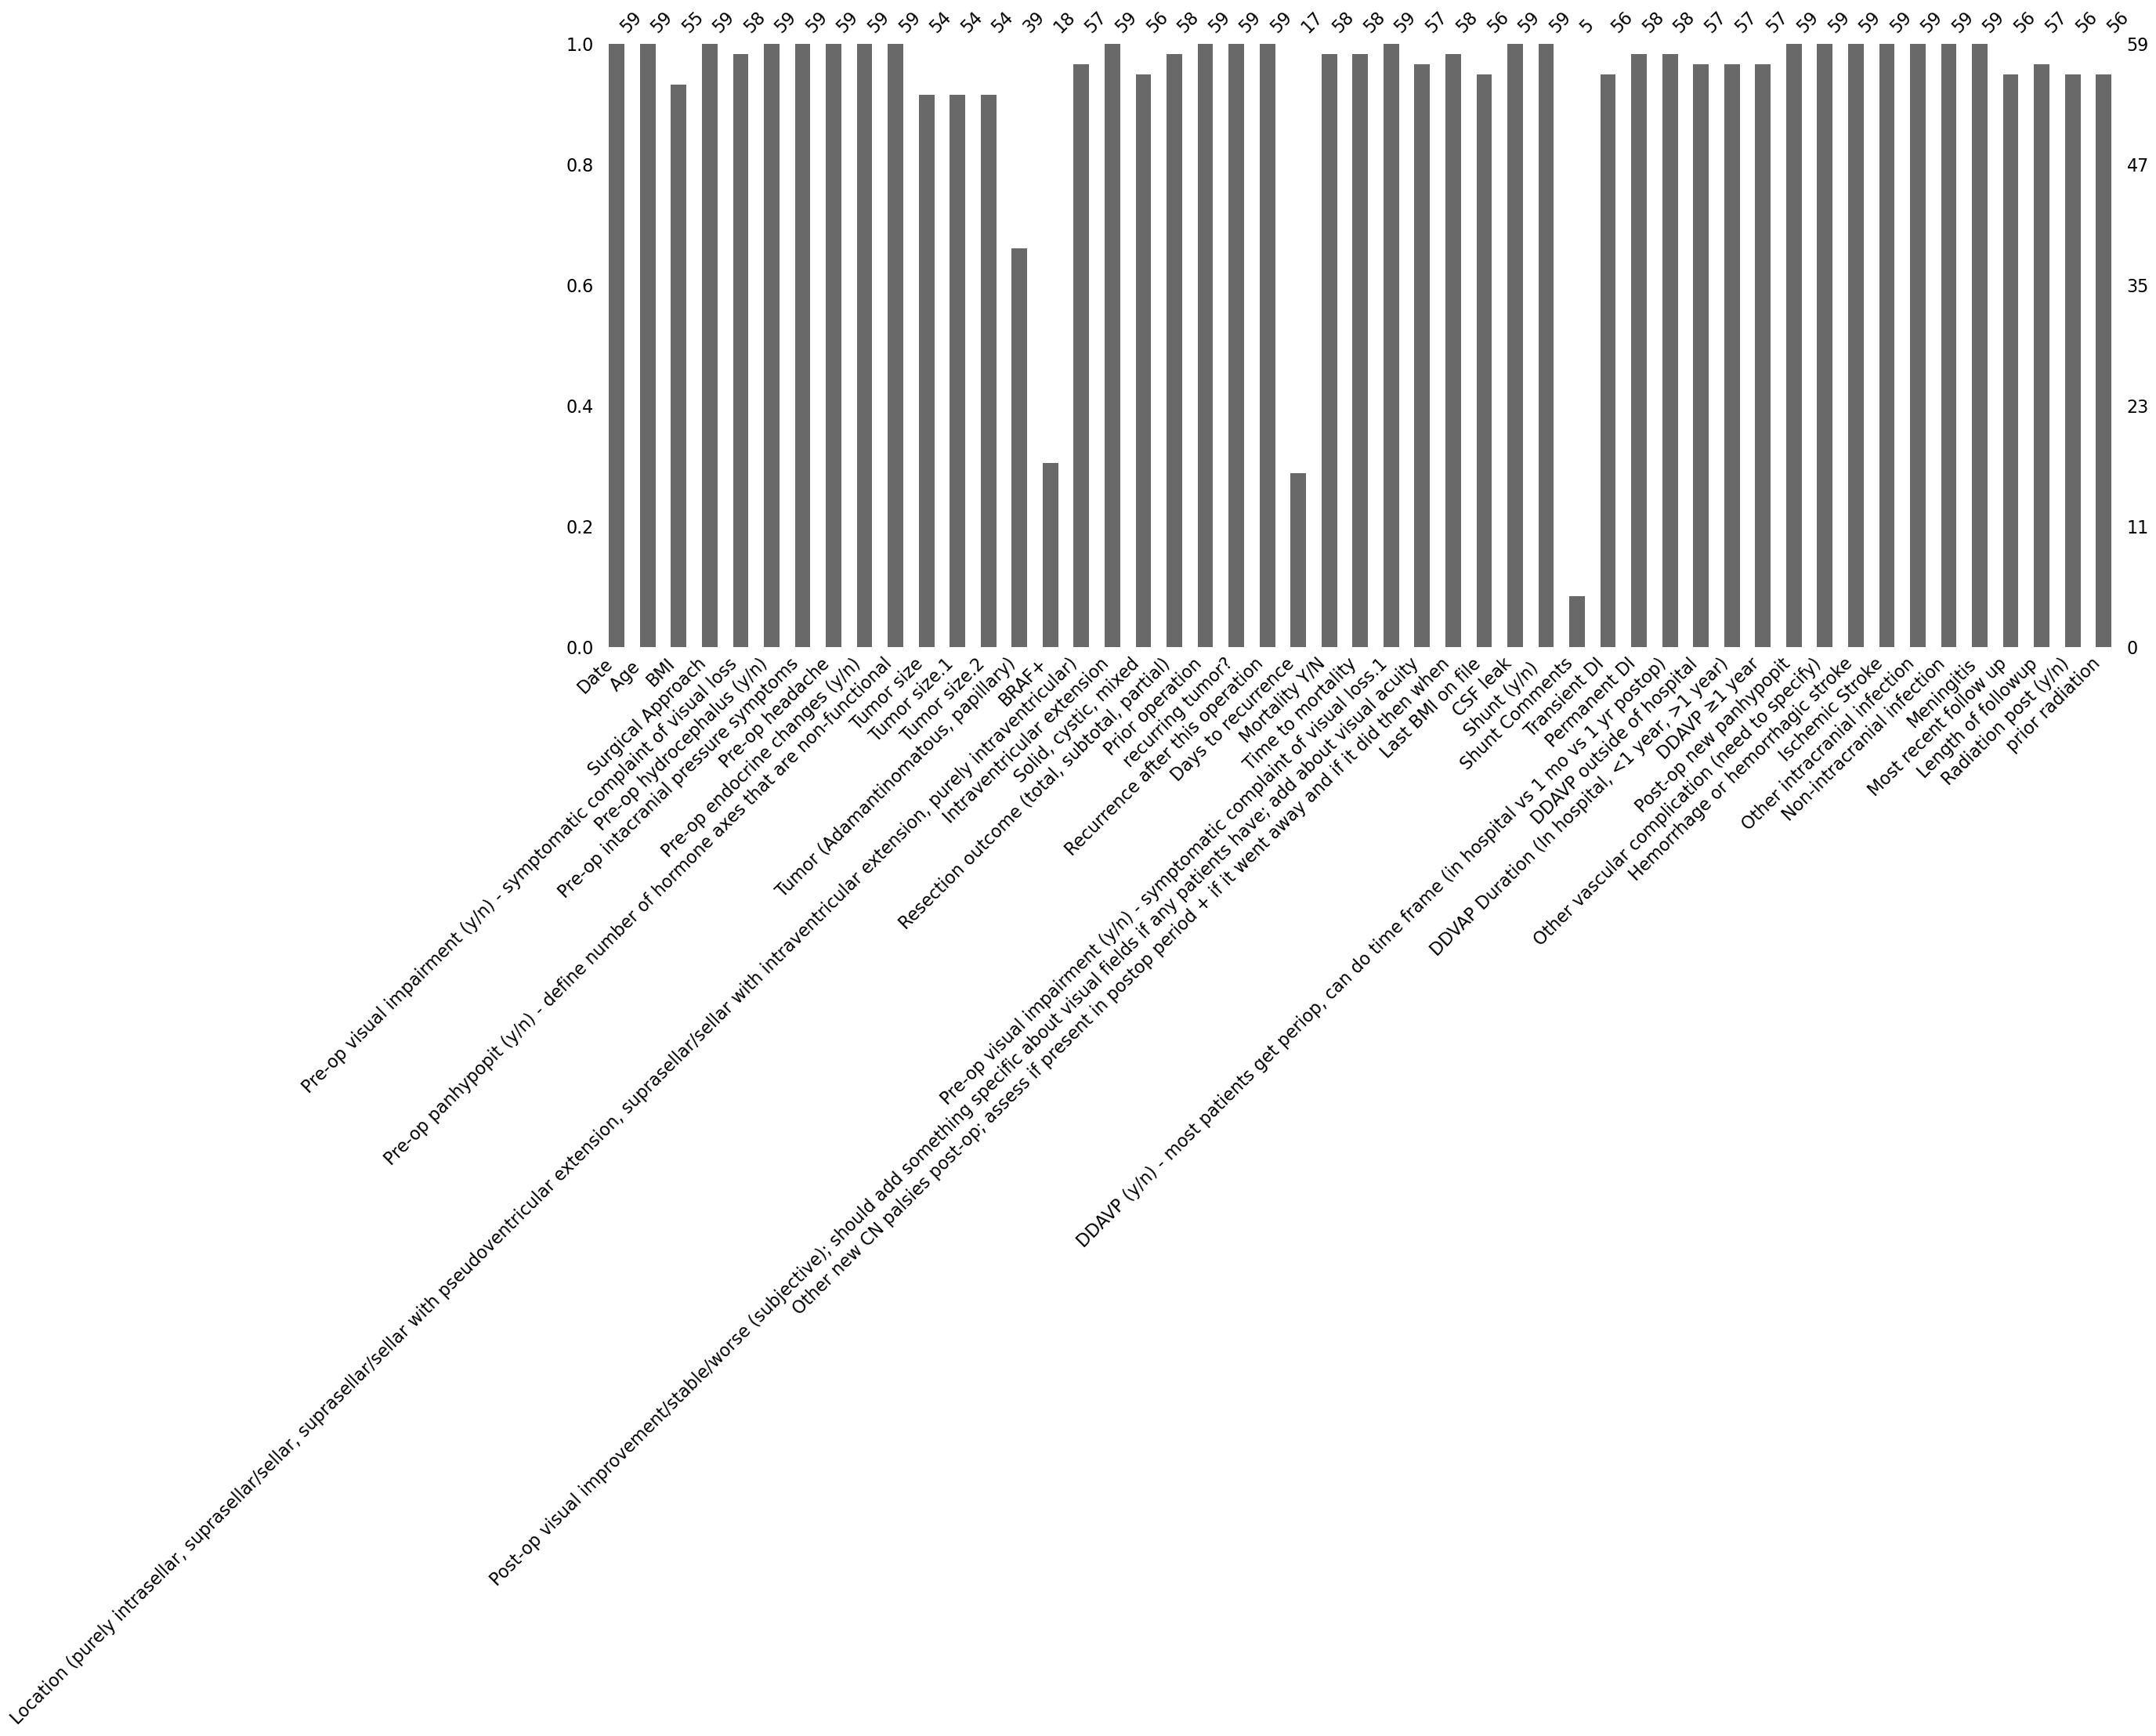

In [3]:
import missingno as msno
import matplotlib.pyplot as plt
# Matrix view of missing values
msno.matrix(df)
plt.show()

# Heatmap of correlations of missingness
msno.heatmap(df)
plt.show()

# Dendrogram clusters variables by missingness similarity
msno.dendrogram(df)
plt.show()


msno.bar(df)
plt.show()

In [ ]:
for col in df.columns:
    n_missing = df[col].isnull().sum()
    if n_missing > 0:
        print(f"{col}: {n_missing} missing values, {n_missing / len(df) * 100:.2f}%")



BMI: 4 missing values, 6.78%
Pre-op visual impairment (y/n) - symptomatic complaint of visual loss: 1 missing values, 1.69%
Tumor size: 5 missing values, 8.47%
Tumor size.1: 5 missing values, 8.47%
Tumor size.2: 5 missing values, 8.47%
Tumor (Adamantinomatous, papillary): 20 missing values, 33.90%
BRAF+: 41 missing values, 69.49%
Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular): 2 missing values, 3.39%
Solid, cystic, mixed: 3 missing values, 5.08%
Resection outcome (total, subtotal, partial): 1 missing values, 1.69%
Days to recurrence: 42 missing values, 71.19%
Mortality Y/N: 1 missing values, 1.69%
Time to mortality: 1 missing values, 1.69%
Post-op visual improvement/stable/worse (subjective); should add something specific about visual fields if any patients have; add about visual acuity: 2 missing values, 3.39%
Other new CN palsies post-op; assess if pres

In [23]:
for col in df.columns:
    if df[col].isnull().sum() / len(df) > 0.15:
        print(f"{col}: {df[col].isnull().sum()} missing values")


Tumor (Adamantinomatous, papillary): 20 missing values
BRAF+: 41 missing values
Days to recurrence: 42 missing values
Shunt Comments: 54 missing values
